In [2]:
import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [3]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [3.2489276324892766, 2.0079477038671003]


### with old dataset and all 16bit

In [ ]:
api = wandb.Api()
results = []
# t_run = tqdm(api.sweep("ddold/subspace_bezier_length_dnn/taa7hglw").runs)
for s in ["yqlk3puv",]:
# for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

yqlk3puv:   0%|          | 0/96 [00:00<?, ?it/s, major-sweep-90]    

yqlk3puv: 100%|██████████| 96/96 [00:00<00:00, 347.09it/s, glowing-sweep-1]   


,Id,NumSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,kz2axb5d,2,16,0.01,boolq,19.841238,0.889375,0.886813,0.289062,0.292969
1,5yzv7v76,2,8,0.01,boolq,19.822430,0.885937,0.883388,0.298828,0.300781
2,bmfwlzr3,2,4,0.01,boolq,19.825733,0.882500,0.880325,0.289062,0.292969
3,kddkh5rk,2,1,0.01,boolq,19.841034,0.884375,0.881288,0.292969,0.294922
4,ogy1fd4y,0,16,0.00,boolq,0.000000,0.888438,0.888437,0.289062,0.289062
...,...,...,...,...,...,...,...,...,...,...
91,40ndqj5o,0,1,0.01,obqa,0.000000,0.894000,0.894000,0.392578,0.392578
92,uabqy14s,0,16,0.01,winogrande_m,0.000000,0.776667,0.776667,0.828125,0.828125
93,bdpj3rs1,0,8,0.01,winogrande_m,0.000000,0.759167,0.759167,0.878906,0.878906
94,lrs0s3bk,0,4,0.01,winogrande_m,0.000000,0.770000,0.770000,0.820312,0.820312


In [89]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,NumSpace,Seed,WeightDecay,Dataset,,,,,


In [90]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
NumSpace [2 0]
Seed [16  8  4  1]
WeightDecay [0.01 0.  ]
Dataset ['boolq' 'ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['NumSpace', 'WeightDecay', 'Dataset'] configs


In [91]:
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [92]:
# Reference accuracy values from table
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}


#### acc

/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From 

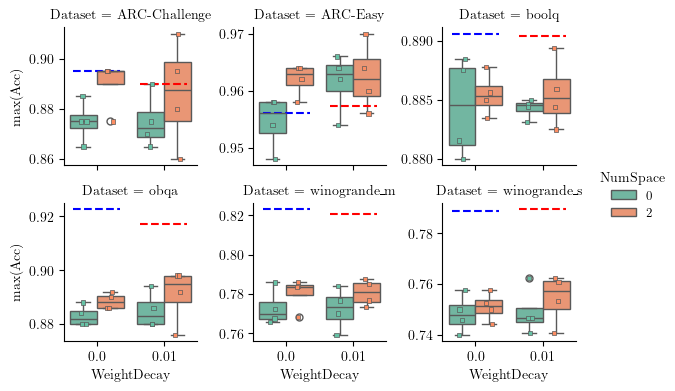

In [ ]:

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )

g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

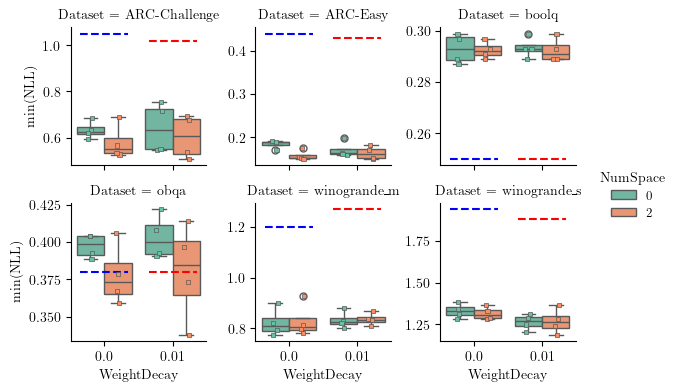

In [ ]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with lora for lmhead and 32bit lora and new dataset

In [10]:
api = wandb.Api()
results = []
for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # drop runs with k>0 because of error in those runs
        if run.config['curve_params']['k'] == 0:
            res = dict(Id=run.id,
                        CurveSpace=run.config['curve_params']['k'],
                        Seed=run.config['rng_seed'],
                        WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                        Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                        bezierLength=run.summary.get('Curve length', 0),
                        acc_max=run.summary['final_acc_max'],
                        acc_mean=run.summary['final_acc_mean'],
                        nll_min=run.summary['final_loss_min'],
                        nll_mean=run.summary['final_loss_mean'],
                )
            results.append(res)

for s in ["0lqp05qb",]: # with lora for lmhead and 32bit lora and new dataset and no bias learning
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)


df = pd.DataFrame(results)
df

vj9z5em9:   0%|          | 0/96 [00:00<?, ?it/s, amber-sweep-67]   

0lqp05qb: 100%|██████████| 48/48 [00:00<00:00, 381.35it/s, glorious-sweep-1]


,Id,CurveSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,z51vrw9d,0,16,0.00,ARC-Easy,0.000000,0.956000,0.9560,0.271484,0.271484
1,ly92c21c,0,8,0.00,ARC-Easy,0.000000,0.958000,0.9580,0.269531,0.269531
2,t1ys9evr,0,4,0.00,ARC-Easy,0.000000,0.960000,0.9600,0.308594,0.308594
3,9581cv0o,0,1,0.00,ARC-Easy,0.000000,0.952000,0.9520,0.269531,0.269531
4,lwra1vhw,0,16,0.00,ARC-Challenge,0.000000,0.885000,0.8850,0.980469,0.980469
...,...,...,...,...,...,...,...,...,...,...
91,ybzhhopf,2,1,0.01,winogrande_s,2323.270752,0.770833,0.7586,1.140625,1.375000
92,8b40jvf1,2,16,0.01,winogrande_m,2322.336426,0.782500,0.7709,0.800781,0.929688
93,0hw1ze77,2,8,0.01,winogrande_m,2322.122070,0.785833,0.7764,0.820312,0.976562
94,uo0yf7tt,2,4,0.01,winogrande_m,2322.653809,0.787500,0.7789,0.804688,0.898438


In [11]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Seed,WeightDecay,Dataset,,,,,


In [12]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0 2]
Seed [16  8  4  1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

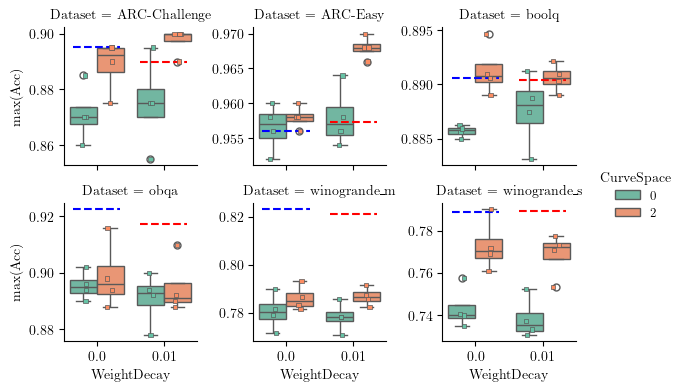

In [13]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

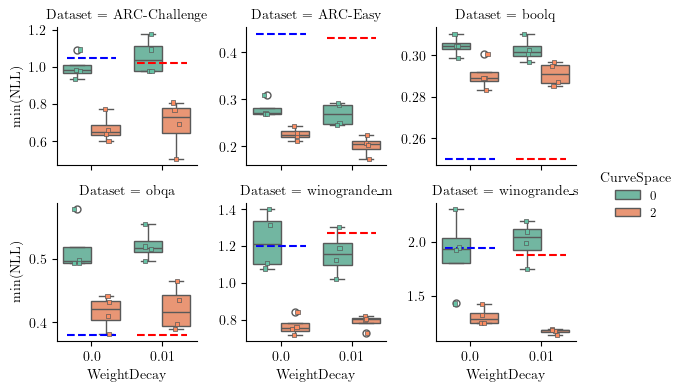

In [14]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### only curve compare with longer training 100_000 steps and different jitter and two new seeds

In [48]:
api = wandb.Api()
results = []
for s in ["tfpynhck",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 72/72 [00:00<00:00, 437.35it/s, devout-sweep-1]        


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xpz4zlz3,2,5.0,7,0.01,ARC-Easy,11583.458984,0.296000,0.254560,1.382812,1.390625
1,u3ecxkwz,2,5.0,6,0.01,ARC-Easy,11584.446289,0.956000,0.938560,0.203125,0.277344
2,yzwme8xu,2,5.0,4,0.01,ARC-Easy,11584.413086,0.282000,0.253280,1.382812,1.390625
3,vpow0gs8,2,5.0,1,0.01,ARC-Easy,11587.439453,0.316000,0.268320,1.398438,1.445312
4,gy40kqo3,2,5.0,7,0.01,ARC-Challenge,11583.307617,0.860000,0.829600,0.843750,0.953125
...,...,...,...,...,...,...,...,...,...,...,...
67,y4geo7qb,2,1.0,7,0.01,winogrande_m,2316.600098,0.783333,0.772900,1.015625,1.156250
68,6en36155,2,1.0,1,0.01,winogrande_s,2317.422363,0.767500,0.752933,1.500000,1.804688
69,3nunf43m,2,1.0,6,0.01,winogrande_m,2316.818848,0.797500,0.786533,0.933594,1.125000
70,12tvj3l9,2,1.0,4,0.01,winogrande_m,2316.797852,0.800833,0.787866,0.933594,1.132812


In [49]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [50]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [5.  0.5 1. ]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['Jitter', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

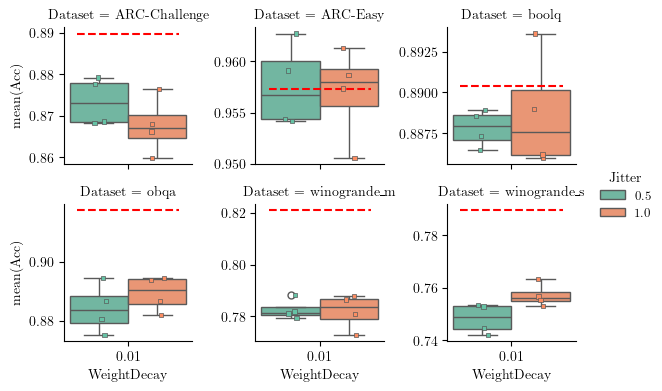

In [51]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}

df_clean = df_clean[df_clean['Jitter']<5]

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

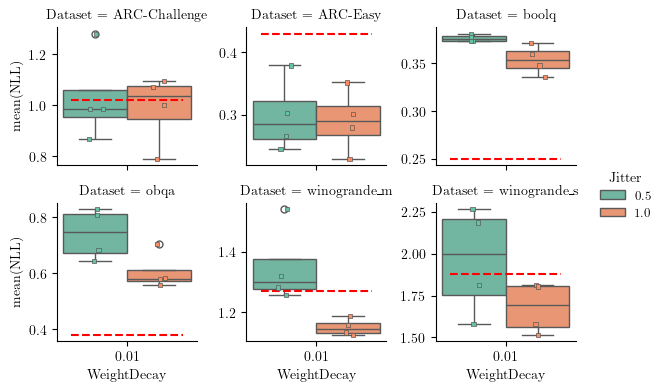

In [52]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### Reruns from scalabl

In [53]:
api = wandb.Api()
results = []
t_run = tqdm(api.runs(f"ddold/MLE-Qwen2.5-7B-all"))
t_run.set_description(s)
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    # drop runs with k>0 because of error in those runs
    res = dict(Id=run.id,
                CurveSpace=0,
                Seed=run.config['seed'],
                Dataset=run.config['dataset'],
                WeightDecay=0,
                acc=run.summary['final_val_acc'],
                nll=run.summary['final_val_nll'],
                ece=run.summary['final_val_ece'],
        )
    results.append(res)


df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 38/38 [00:00<00:00, 2255.51it/s, mle-boolq-seed3]


,Id,CurveSpace,Seed,Dataset,WeightDecay,acc,nll,ece
0,o1dulwhl,0,6,winogrande_s,0,0.779272,2.031250,0.205545
1,wgxbatmk,0,2,winogrande_s,0,0.775316,2.500000,0.218704
2,qvw1l26p,0,2,winogrande_s,0,0.775316,2.500000,0.218704
3,rn2t593s,0,6,winogrande_s,0,0.779272,2.031250,0.205545
4,4vjwwd1s,0,2,ARC-Challenge,0,0.898649,1.023438,0.104334
5,qo0agtmt,0,6,ARC-Challenge,0,0.898649,1.148438,0.100098
6,2ztl882y,0,6,ARC-Easy,0,0.954225,0.433594,0.042859
7,9k88c90n,0,2,ARC-Easy,0,0.955986,0.457031,0.039833
8,eu6ogm6l,0,2,winogrande_m,0,0.816456,1.203125,0.162480
9,tspr1v8i,0,6,winogrande_m,0,0.829114,1.132812,0.151753


In [54]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,acc,nll,ece
Id,CurveSpace,Seed,Dataset,WeightDecay,,,


In [55]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0]
Seed [6 2 7 4 3 5]
Dataset ['winogrande_s' 'ARC-Challenge' 'ARC-Easy' 'winogrande_m' 'obqa' 'boolq']
WeightDecay [0]

Experiment differs in ['Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

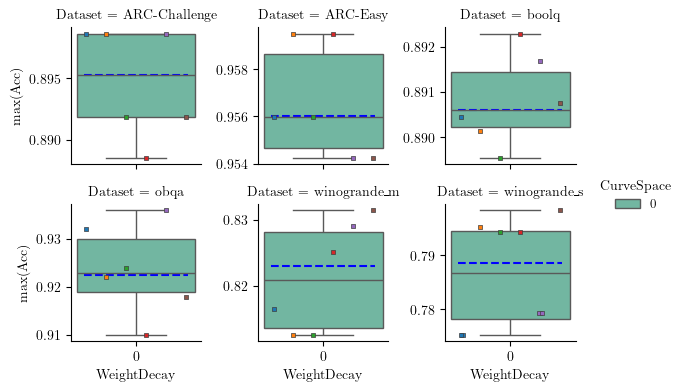

In [56]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

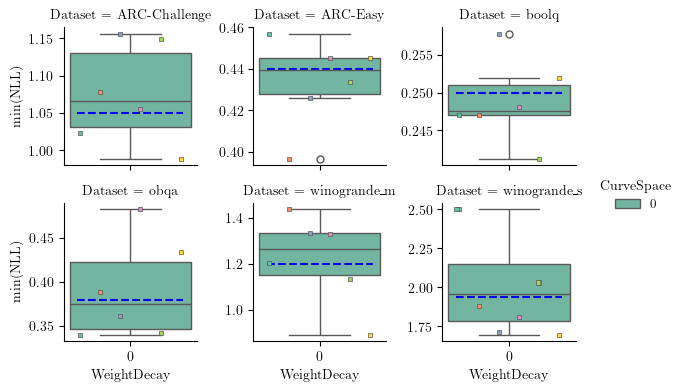

In [59]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with new scaling behavior for LoRA (lora_alpha parameter)

In [4]:
api = wandb.Api()
results = []
for s in ["5qmpsskt",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

5qmpsskt:   0%|          | 0/40 [00:00<?, ?it/s, leafy-sweep-21]   

5qmpsskt: 100%|██████████| 40/40 [00:00<00:00, 430.25it/s, glamorous-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,ctce5vis,2,1,7,0.01,ARC-Easy,2322.504150,0.286000,0.254000,1.382812,1.382812
1,wanqj2ar,2,1,6,0.01,ARC-Easy,2322.728516,0.314000,0.262720,1.375000,1.382812
2,u9xvovko,2,1,4,0.01,ARC-Easy,2322.689453,0.300000,0.257920,1.375000,1.390625
3,948siewz,2,1,1,0.01,ARC-Easy,2323.303711,0.310000,0.260480,1.382812,1.390625
4,e568ou5g,2,1,7,0.01,ARC-Challenge,2322.484863,0.315000,0.279200,1.382812,1.484375
5,2f2n4smv,2,1,6,0.01,ARC-Challenge,2322.709717,0.310000,0.273400,1.390625,1.390625
6,iqrc2jd6,2,1,4,0.01,ARC-Challenge,2322.682129,0.310000,0.266200,1.390625,1.390625
7,c85gkqkv,2,1,1,0.01,ARC-Challenge,2323.312988,0.335000,0.266600,1.382812,1.390625
8,n3dnw2vz,2,1,7,0.01,obqa,2322.505615,0.252000,0.252000,1.382812,1.382812
9,unr0x2r3,2,1,6,0.01,obqa,2322.716064,0.314000,0.266960,1.382812,1.382812


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


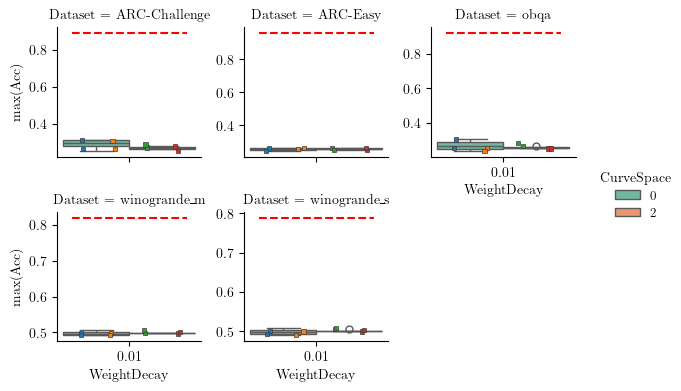

In [9]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


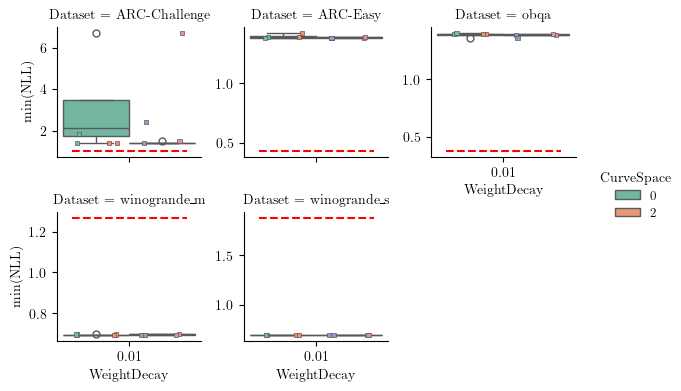

In [10]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### changed lora A matrix initialization to he_uniform 
(from he normal) with a leak_relu gain

In [11]:
api = wandb.Api()
results = []
for s in ["xe2hkb5h",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

xe2hkb5h:   0%|          | 0/48 [00:00<?, ?it/s, fragrant-sweep-39] 

xe2hkb5h: 100%|██████████| 48/48 [00:00<00:00, 227.18it/s, radiant-sweep-1]  


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,f4vwob68,2,1,7,0.01,ARC-Easy,2322.484619,0.294000,0.256960,1.382812,1.398438
1,w91ihub4,2,1,6,0.01,ARC-Easy,2322.701660,0.300000,0.257520,1.382812,1.390625
2,be2i28qa,2,1,4,0.01,ARC-Easy,2322.699219,0.296000,0.255920,1.375000,1.390625
3,2mntsbow,2,1,1,0.01,ARC-Easy,2323.312988,0.302000,0.261360,1.382812,1.398438
4,4d45ttle,2,1,7,0.01,ARC-Challenge,2322.492676,0.315000,0.257200,1.382812,1.398438
5,zx3k8ld6,2,1,6,0.01,ARC-Challenge,2322.723633,0.335000,0.284800,1.382812,1.390625
6,lfk4yxrz,2,1,4,0.01,ARC-Challenge,2322.675781,0.340000,0.291400,1.367188,1.390625
7,5e3fqg5w,2,1,1,0.01,ARC-Challenge,2323.314453,0.310000,0.257600,1.382812,1.390625
8,sr27gufy,2,1,7,0.01,obqa,2322.490234,0.276000,0.254880,1.382812,1.390625
9,7zonu1nu,2,1,6,0.01,obqa,2322.706543,0.280000,0.255840,1.382812,1.382812


In [12]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [13]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

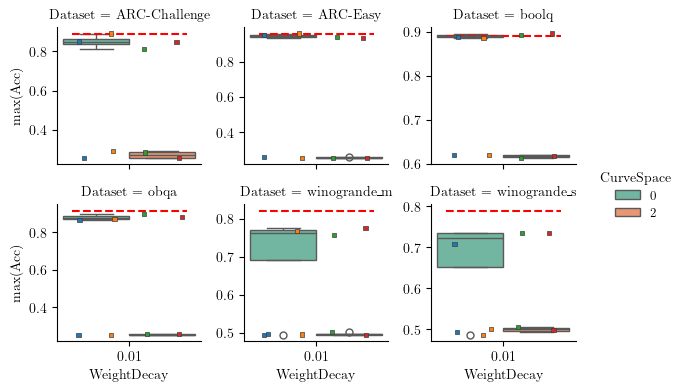

In [15]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

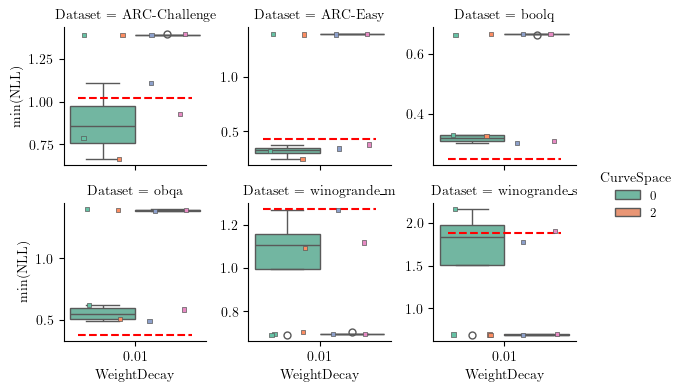

In [16]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and no noise for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ no noise for curve

In [5]:
api = wandb.Api()
results = []
for s in ["0nx704d3",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

0nx704d3:   0%|          | 0/48 [00:00<?, ?it/s, vivid-sweep-37]   

0nx704d3: 100%|██████████| 48/48 [00:00<00:00, 392.13it/s, glorious-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xqosvrr7,2,0,7,0.01,ARC-Easy,6.144023,0.956000,0.953440,0.343750,0.378906
1,ww08b05p,2,0,6,0.01,ARC-Easy,5.367301,0.968000,0.963760,0.287109,0.310547
2,mx0bd9k4,2,0,1,0.01,ARC-Easy,5.832235,0.966000,0.959280,0.222656,0.253906
3,96c2xhyj,2,0,4,0.01,ARC-Easy,5.940700,0.968000,0.964160,0.279297,0.292969
4,re7621i7,2,0,7,0.01,ARC-Challenge,5.046455,0.905000,0.895600,0.984375,1.078125
5,dcm2faci,2,0,6,0.01,ARC-Challenge,5.842677,0.900000,0.892400,0.746094,0.781250
6,ajw1nfxq,2,0,1,0.01,ARC-Challenge,6.049755,0.915000,0.907400,0.765625,0.804688
7,0dygel1f,2,0,4,0.01,ARC-Challenge,5.509381,0.895000,0.883200,0.964844,1.093750
8,j4a0fy81,2,0,7,0.01,obqa,7.142587,0.922000,0.915520,0.419922,0.435547
9,rmx5x2ji,2,0,1,0.01,obqa,7.455338,0.910000,0.902640,0.398438,0.449219


In [6]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [7]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [0]
Seed [7 6 1 4]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

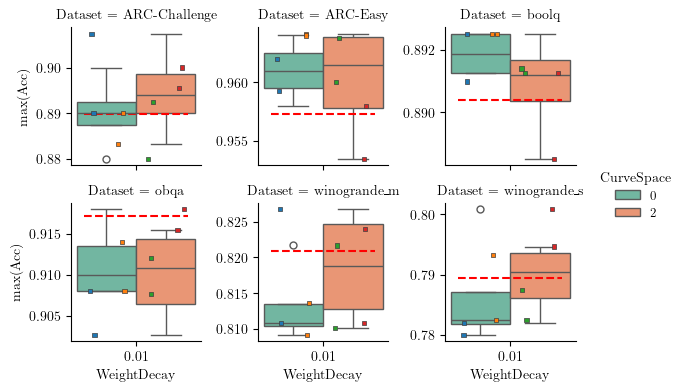

In [8]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

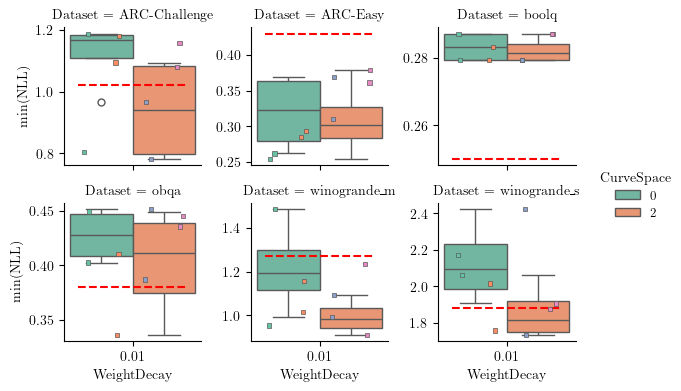

In [9]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and he_uniform init for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [4]:
api = wandb.Api()
results = []
for s in ["ev8m11oc",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

ev8m11oc: 100%|██████████| 6/6 [00:00<00:00, 2619.26it/s, eternal-sweep-1]

Skipping faithful-sweep-6 because it is not finished
Skipping devoted-sweep-5 because it is not finished
Skipping eager-sweep-4 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,63nt1ad7,2,0,6,0.01,winogrande_m,25.136360,0.826667,0.821833,0.992188,1.054688
1,mp774kh1,2,0,4,0.01,winogrande_m,25.093098,0.831667,0.824700,0.878906,0.902344
2,ef7s73xu,2,0,1,0.01,winogrande_m,25.058437,0.825833,0.821833,0.765625,0.894531


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [0]
Seed [6 4 1]
WeightDecay [0.01]
Dataset ['winogrande_m']

Experiment differs in [] configs


array(['winogrande_m'], dtype=object)

#### acc

/tmp/ipykernel_435398/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


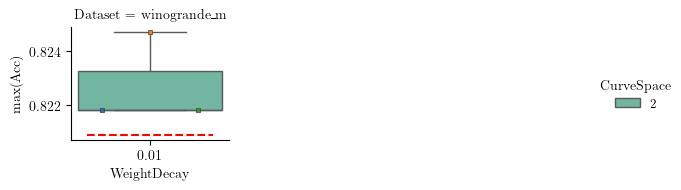

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_435398/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


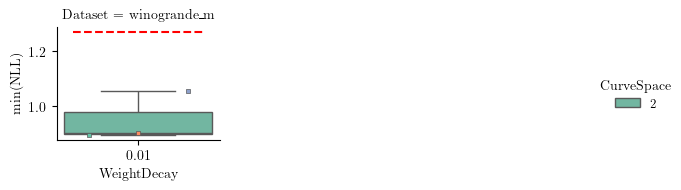

In [8]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### test
